This part is code execution

In [ ]:
import yfinance as yf
from sklearn.model_selection import TimeSeriesSplit

data = yf.download("MC.PA", start="2018-01-01", end="2025-12-31")

tscv = TimeSeriesSplit(n_splits=4)
for train_index, test_index in tscv.split(data):
    print("Train:", data.index[train_index[0]].date(), "to", data.index[train_index[-1]].date())
    print("Test: ", data.index[test_index[0]].date(), "to", data.index[test_index[-1]].date())
    print()

/tmp/ipykernel_1112/297039353.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download("MC.PA", start="2018-01-01", end="2025-12-31")
[*********************100%***********************]  1 of 1 completed

Train: 2018-01-02 to 2019-08-13
Test:  2019-08-14 to 2021-03-17

Train: 2018-01-02 to 2021-03-17
Test:  2021-03-18 to 2022-10-17

Train: 2018-01-02 to 2022-10-17
Test:  2022-10-18 to 2024-05-24

Train: 2018-01-02 to 2024-05-24
Test:  2024-05-27 to 2025-12-30



In [ ]:
!pip install backtesting -q

# **1. Setup & Configuration**

In [ ]:
%%capture
!pip install -q exchange_calendars python-dotenv

import os, json, requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
import pytz
import math
import time
from datetime import datetime, timedelta, time as dt_time
from IPython.display import display, Markdown
from dotenv import load_dotenv

load_dotenv()

# ===== Configuration =====
API_KEY_ID     = os.environ.get("PKPV2VLY6IDGINJLJWNIPHTJQV", "")
API_SECRET_KEY = os.environ.get("9t29KTvAgLWshJWo8HEP5YokbtRqDNtJoKcTUGXUyoTf", "")

TICKER     = "TQQQ"
START_DATE = "2016-01-01"
END_DATE   = "2026-10-20"

TIMEFRAME  = "30Min"
orb_m      = 30             # Opening range (minutes)
target_R_HL  = 10          # H/L mode: profit target at 10x stop distance
target_R_ATR = float('inf')  # ATR mode: no profit target (hold to close)
commission = 0.0010        # Per-share commission
risk       = 0.01          # Equity risk per trade
max_Lev    = 4             # Max leverage
AUM_0      = 10000         # Starting capital
stop_atr   = 0.05          # ATR stop multiplier (fraction of ATR%)

ACTIVE_PROVIDERS = ["Alpaca"]

# =============================================================================
# End of configuration
# =============================================================================

utc_tz = pytz.timezone('UTC')
nyc_tz = pytz.timezone('America/New_York')

os.makedirs("data/alpaca", exist_ok=True)

# **2. Data Download**

This section downloads intraday and daily data from Alpaca. Intraday bars are **unadjusted** (raw prices for trading). Daily bars use `adjustment=all` so Alpaca returns them **fully adjusted** for splits and dividends.

**Output** (`data/alpaca/`):
- `{TICKER}_intraday.csv` - RTH 30-minute bars (unadjusted)
- `{TICKER}_daily.csv` - daily OHLC (fully adjusted)

In [ ]:
# ===== Trade log (INSERTED) =====
trade_log = []     # INSERTED
trade_id  = 0      # INSERTED

def log_trade(current_day, side, entry_ts, entry, stop_price, target_price,   # INSERTED
              target_R, exit_ts, exit_price, exit_reason, shares, PnL_T,
              aum_before, aum_after):
    global trade_id
    trade_id += 1
    trade_log.append({
        'TradeID'    : trade_id,
        'Date'       : current_day,
        'Side'       : 'Long' if side == 1 else 'Short',
        'EntryTime'  : entry_ts,
        'EntryPx'    : entry,
        'StopPx'     : stop_price,
        'TargetPx'   : target_price if np.isfinite(target_R) else np.nan,
        'ExitTime'   : exit_ts,
        'ExitPx'     : exit_price,
        'ExitReason' : exit_reason,
        'Shares'     : shares,
        'PnL_$'      : shares * PnL_T,
        'PnL_R'      : (shares * PnL_T) / (risk * aum_before),
        'AUM_After'  : aum_after
    })

def save_trades():   # INSERTED
    trades_df = pd.DataFrame(trade_log)
    display(trades_df.head())
    trades_df.to_csv(f"data/{TICKER}_trades_{TIMEFRAME}.csv", index=False)
    return trades_df

# ===== Data download =====
ALP_INTRADAY = f"data/alpaca/{TICKER}_intraday_{TIMEFRAME}.csv"   # CHANGED
ALP_DAILY    = f"data/alpaca/{TICKER}_daily.csv"

def get_alpaca_data(symbol=TICKER, timeframe=TIMEFRAME,          # CHANGED
                    start_date=START_DATE, end_date=END_DATE,
                    max_retries=5, delay=0.35):
    base_url = "https://data.alpaca.markets/v2/stocks/bars"
    headers = {"APCA-API-KEY-ID": API_KEY_ID, "APCA-API-SECRET-KEY": API_SECRET_KEY}
    params = {
        "symbols": symbol, "timeframe": timeframe,
        "start": datetime.strptime(start_date, "%Y-%m-%d").isoformat() + "Z",
        "end": (datetime.strptime(end_date, "%Y-%m-%d") + timedelta(days=1)).isoformat() + "Z",
        "limit": 10000, "adjustment": "raw", "feed": "sip",
    }
    all_results = []
    batch = 0
    while True:
        batch += 1
        for attempt in range(max_retries):
            try:
                response = requests.get(base_url, headers=headers, params=params, timeout=30)
                if response.status_code == 429:
                    wait = int(response.headers.get("Retry-After", 2 ** attempt))
                    print(f"  Rate limited, waiting {wait}s...")
                    time.sleep(wait)
                    continue
                if response.status_code != 200:
                    print(f"Error {response.status_code}: {response.text}")
                    if attempt < max_retries - 1:
                        time.sleep(2 ** attempt)
                        continue
                    raise RuntimeError(f"API returned {response.status_code} after {max_retries} retries. "
                                       f"Downloaded {len(all_results):,} bars before failure.")
                break
            except (requests.exceptions.ConnectionError, requests.exceptions.Timeout) as e:
                if attempt < max_retries - 1:
                    wait = 2 ** (attempt + 1)
                    print(f"  Batch {batch} attempt {attempt+1} failed ({type(e).__name__}), retrying in {wait}s...")
                    time.sleep(wait)
                else:
                    raise RuntimeError(f"Batch {batch} failed after {max_retries} attempts. "
                                       f"Downloaded {len(all_results):,} bars before failure. "
                                       f"Delete the cached CSV and re-run.")
        data = response.json()
        bars = data.get("bars", {})
        batch_results = []
        for sym, entries in bars.items():
            for entry in entries:
                entry["symbol"] = sym
                batch_results.append(entry)
        if not batch_results:
            break
        if batch % 10 == 1:
            print(f"  Batch {batch}: {len(batch_results)} bars (total: {len(all_results):,})")
        all_results.extend(batch_results)
        npt = data.get("next_page_token")
        if not npt:
            break
        params["page_token"] = npt
        time.sleep(delay)
    print(f"  Downloaded {len(all_results):,} bars in {batch} batches")
    return all_results


def process_alpaca_intraday(results):
    df = pd.DataFrame(results)
    df["datetime_utc"] = pd.to_datetime(df["t"])
    df["datetime_et"] = df["datetime_utc"].dt.tz_convert(nyc_tz)
    df["caldt"] = df["datetime_et"].dt.tz_localize(None)
    df = df.set_index("datetime_et")
    df = df.between_time("09:30", "15:59").reset_index()
    df["date"] = df["datetime_et"].dt.date
    df = df.rename(columns={"v": "volume", "o": "open", "c": "close", "h": "high", "l": "low", "t": "timestamp_iso"})
    df["day"] = df["date"]
    df["vwap"] = np.nan
    df["timestamp_ms"] = df["datetime_utc"].astype(np.int64) // 10**6
    df["transactions"] = np.nan
    cols = ["datetime_et", "volume", "vwap", "open", "close", "high", "low",
            "timestamp_ms", "transactions", "datetime_utc", "caldt", "date", "day"]
    return df[cols]


def download_daily_alpaca(ticker, start_date, end_date):
    atr_start = (datetime.strptime(start_date, "%Y-%m-%d") - timedelta(days=45)).strftime("%Y-%m-%d")
    base_url = "https://data.alpaca.markets/v2/stocks/bars"
    headers = {"APCA-API-KEY-ID": API_KEY_ID, "APCA-API-SECRET-KEY": API_SECRET_KEY}
    all_bars = []
    page_token = None
    while True:
        params = {"symbols": ticker, "timeframe": "1Day", "start": atr_start,
                  "end": (datetime.strptime(end_date, "%Y-%m-%d") + timedelta(days=1)).strftime("%Y-%m-%d"),
                  "limit": 10000, "adjustment": "all", "feed": "sip"}
        if page_token:
            params["page_token"] = page_token
        resp = requests.get(base_url, headers=headers, params=params, timeout=30)
        if resp.status_code == 429:
            time.sleep(int(resp.headers.get("Retry-After", 5)))
            continue
        if resp.status_code != 200:
            raise Exception(f"Alpaca error {resp.status_code}: {resp.text}")
        body = resp.json()
        bars = body.get("bars", {}).get(ticker, [])
        all_bars.extend(bars)
        page_token = body.get("next_page_token")
        if not page_token:
            break
        time.sleep(0.35)
    df = pd.DataFrame(all_bars)
    df["day"] = pd.to_datetime(df["t"]).dt.tz_convert(nyc_tz).dt.date
    df = df.rename(columns={"o": "open", "h": "high", "l": "low", "c": "close"})
    return df[["day", "open", "high", "low", "close"]].drop_duplicates(subset="day").sort_values("day").reset_index(drop=True)


if os.path.exists(ALP_INTRADAY):
    print(f"Alpaca intraday cached: {ALP_INTRADAY}")
else:
    print(f"Downloading Alpaca intraday data ({TIMEFRAME})...")   # CHANGED
    raw = get_alpaca_data()
    alpaca_intra = process_alpaca_intraday(raw)
    alpaca_intra.to_csv(ALP_INTRADAY, index=False)
    print(f"Saved {len(alpaca_intra):,} bars to {ALP_INTRADAY}")

if os.path.exists(ALP_DAILY):
    print(f"Alpaca daily cached: {ALP_DAILY}")
else:
    print("Downloading Alpaca daily data (fully adjusted: splits + dividends)...")
    alp_daily = download_daily_alpaca(TICKER, START_DATE, END_DATE)
    alp_daily.to_csv(ALP_DAILY, index=False)
    print(f"Saved {len(alp_daily)} rows to {ALP_DAILY}")

  Batch 1: 535 bars (total: 0)
  Batch 11: 605 bars (total: 5,809)
  Batch 21: 591 bars (total: 11,659)
  Batch 31: 525 bars (total: 17,095)
  Batch 41: 487 bars (total: 21,946)
  Batch 51: 483 bars (total: 26,791)
  Batch 61: 372 bars (total: 31,199)
  Batch 71: 387 bars (total: 35,164)
  Batch 81: 409 bars (total: 39,125)
  Batch 91: 385 bars (total: 43,181)
  Batch 101: 345 bars (total: 46,802)
  Batch 111: 335 bars (total: 50,177)
  Batch 121: 336 bars (total: 53,526)
  Batch 131: 345 bars (total: 56,940)
  Batch 141: 356 bars (total: 60,415)
  Batch 151: 359 bars (total: 63,947)
  Batch 161: 345 bars (total: 67,448)
  Batch 171: 334 bars (total: 70,873)
  Batch 181: 352 bars (total: 74,285)
  Batch 191: 337 bars (total: 77,693)
  Batch 201: 335 bars (total: 81,047)
  Downloaded 83,098 bars in 207 batches
Saved 35,288 bars to data/alpaca/TQQQ_intraday_30Min.csv
Saved 2716 rows to data/alpaca/TQQQ_daily.csv


In [ ]:
print("ID empty?    ", API_KEY_ID == "")
print("SECRET empty?", API_SECRET_KEY == "")
print("ID starts with:", API_KEY_ID[:2])

ID empty?     True
SECRET empty? True
ID starts with: 


In [ ]:
from getpass import getpass

API_KEY_ID     = getpass("Alpaca Key ID: ")
API_SECRET_KEY = getpass("Alpaca Secret Key: ")

print("ID empty?    ", API_KEY_ID == "")
print("SECRET empty?", API_SECRET_KEY == "")

Alpaca Key ID: ··········
Alpaca Secret Key: ··········
ID empty?     False
SECRET empty? False


In [ ]:
API_KEY_ID     = API_KEY_ID.strip()
API_SECRET_KEY = API_SECRET_KEY.strip()

print("ID starts with:", API_KEY_ID[:2], "| length:", len(API_KEY_ID))
print("Secret length :", len(API_SECRET_KEY))

h = {"APCA-API-KEY-ID": API_KEY_ID, "APCA-API-SECRET-KEY": API_SECRET_KEY}

r1 = requests.get("https://paper-api.alpaca.markets/v2/account", headers=h)
print("Paper account test:", r1.status_code)

r2 = requests.get("https://api.alpaca.markets/v2/account", headers=h)
print("Live account test :", r2.status_code)

ID starts with: ht | length: 35
Secret length : 35
Paper account test: 401
Live account test : 401


In [ ]:
from getpass import getpass

API_KEY_ID     = getpass("Alpaca Key ID: ").strip()
API_SECRET_KEY = getpass("Alpaca Secret Key: ").strip()

print("ID starts with:", API_KEY_ID[:2], "| length:", len(API_KEY_ID))
print("Secret length :", len(API_SECRET_KEY))

In [ ]:
from getpass import getpass

API_KEY_ID     = getpass("Alpaca Key ID: ").strip()
API_SECRET_KEY = getpass("Alpaca Secret Key: ").strip()

print("ID starts with:", API_KEY_ID[:2], "| length:", len(API_KEY_ID))
print("Secret length :", len(API_SECRET_KEY))

Alpaca Key ID: ··········
Alpaca Secret Key: ··········
ID starts with: PK | length: 26
Secret length : 44


**3. Load Formatted Data & Compute ATR%**

Load the standardized intraday CSV and compute ATR% lookups from the fully-adjusted daily data. ATR% is the 14-day ATR divided by the daily open, a normalized ratio unaffected by splits or dividends.

In [ ]:
alpaca_df    = pd.read_csv(ALP_INTRADAY, parse_dates=["caldt", "day"])
alpaca_days    = pd.DatetimeIndex(sorted(alpaca_df["day"].unique()))

datasets = {
    "Alpaca":   (alpaca_df,    alpaca_days),
}

print("Dataset Summary:")
print(f"{'Provider':<12} {'Bars':>10} {'Start':<28} {'End':<28}")
print("-" * 80)
for name, (df, _) in datasets.items():
    print(f"{name:<12} {len(df):>10,} {str(df['datetime_et'].min()):<28} {str(df['datetime_et'].max()):<28}")

# --- Compute ATR% lookups ---

def compute_atr_pct_lookup(daily_df, period=14):
    """Return {date: atr_pct} where atr_pct = ATR(14) / daily_open, lagged by 1 day."""
    df = daily_df.sort_values("day").reset_index(drop=True)
    high_low = df["high"] - df["low"]
    high_close = np.abs(df["high"] - df["close"].shift(1))
    low_close = np.abs(df["low"] - df["close"].shift(1))
    ranges = pd.concat([high_low, high_close, low_close], axis=1)
    true_range = ranges.max(axis=1)
    atr = true_range.rolling(window=period, min_periods=period).mean()
    atr_pct = atr / df["open"]
    df["atr_pct_lag"] = atr_pct.shift(1)
    return dict(zip(df["day"], df["atr_pct_lag"]))


def load_daily_csv(path):
    df = pd.read_csv(path)
    df["day"] = pd.to_datetime(df["day"]).dt.date
    return df


daily_sources = {
    "Alpaca":   ALP_DAILY,
}

atr_pct_lookups = {}
for name, path in daily_sources.items():
    if os.path.exists(path):
        ddf = load_daily_csv(path)
        atr_pct_lookups[name] = compute_atr_pct_lookup(ddf)
        print(f"  {name:>10s}: ATR% lookup ready ({len(atr_pct_lookups[name])} days) from {path}")
    else:
        print(f"  {name:>10s}: daily file not found at {path}")

provider_atr_pct_map = {}
for name in datasets:
    if name in atr_pct_lookups:
        provider_atr_pct_map[name] = atr_pct_lookups[name]

print(f"\nATR% lookups assigned for {len(provider_atr_pct_map)} providers")

print("\nATR% coverage (first -> last valid date):")
for name, lookup in atr_pct_lookups.items():
    valid = sorted([d for d, v in lookup.items() if v is not None and not np.isnan(v)])
    if valid:
        print(f"  {name:>10s}: {valid[0]} to {valid[-1]}  ({len(valid)} days)")
    else:
        print(f"  {name:>10s}: NO valid ATR%!")

Dataset Summary:
Provider           Bars Start                        End                         
--------------------------------------------------------------------------------
Alpaca           35,288 2016-01-04 09:30:00-05:00    2026-10-20 15:30:00-04:00   
      Alpaca: ATR% lookup ready (2716 days) from data/alpaca/TQQQ_daily.csv

ATR% lookups assigned for 1 providers

ATR% coverage (first -> last valid date):
      Alpaca: 2016-01-25 to 2026-10-21  (2702 days)


**4. Filter Early-Close Days**

On early-close days (Black Friday, Christmas Eve, July 3rd) the market closes at 13:00 ET instead of 16:00 ET. Some data feeds include bars after the real close. This cell generates the NYSE calendar using exchange_calendars and removes those post-close bars.

In [ ]:
import exchange_calendars as excal

nyse = excal.get_calendar("XNYS")
nyse_sessions = nyse.sessions_in_range("2015-01-01", nyse.last_session)
nyse_close_utc = nyse.schedule.loc[nyse_sessions, "close"]
nyse_close_et = nyse_close_utc.dt.tz_convert("US/Eastern")
early_dates = set(nyse.early_closes.date)

ec_close_map = {}
for sess, close_t in zip(nyse_sessions, nyse_close_et):
    if sess.date() in early_dates:
        ec_close_map[sess.date()] = close_t.hour * 60 + close_t.minute

print(f"Early-close days in calendar: {len(ec_close_map)}\n")

for name in list(datasets.keys()):
    df, days = datasets[name]

    bar_minutes = df["caldt"].dt.hour * 60 + df["caldt"].dt.minute
    bar_date = df["day"].dt.date

    close_thresh = bar_date.map(ec_close_map)
    is_early_day = close_thresh.notna()
    close_thresh = close_thresh.fillna(960).astype(int)

    remove = is_early_day & (bar_minutes >= close_thresh)

    n_removed = remove.sum()
    if n_removed > 0:
        affected = df[remove].groupby(df[remove]["day"].dt.date).size()
        df_filtered = df[~remove].reset_index(drop=True)
        days_filtered = pd.DatetimeIndex(sorted(df_filtered["day"].unique()))
        datasets[name] = (df_filtered, days_filtered)
        print(f"  {name:>10s}: removed {n_removed:>5d} bars across {len(affected)} early-close days")
    else:
        print(f"  {name:>10s}: clean")

alpaca_df, alpaca_days = datasets["Alpaca"]

print(f"\nFiltered bar counts:")
for name, (df, _) in datasets.items():
    print(f"  {name:>10s}: {len(df):>10,} bars")

Early-close days in calendar: 25

      Alpaca: removed   120 bars across 21 early-close days

Filtered bar counts:
      Alpaca:     35,168 bars


**5. The ORB Strategy**

The Opening Range Breakout strategy works as follows:

    Observe the first 30 minutes of trading (the "opening range")
    Determine direction: If the close of the Nth bar > open of the 1st bar → Long; if lower → Short; if equal → skip. This uses the net direction of the opening range, not a breakout above/below the range extremes.
    Enter at the open of the (N+1)th bar
    Stop loss - two modes:
        H/L: high (for shorts) or low (for longs) of the opening range
        ATR: the stop width (in )is‘stopatrmult∗ATR2 stop width on a 100entrymeansthestopisplacedat98.
    Profit target: H/L mode exits at 10x the stop distance; ATR mode holds to close (no target)
    Position sizing based on fixed fractional risk (1% of equity per trade)

This implementation uses a 30-minute opening range with no profit target (hold until stop or close).

## 5. The ORB Strategy

The Opening Range Breakout strategy works as follows:

1. **Opening range (CHANGED):** Observe the first 30 minutes of trading. With 30-minute bars, this is exactly **one bar** (9:30 to 10:00).
2. **Direction (CHANGED):** If the close of this bar > its open → Long. If lower → Short. If equal → skip. This uses the net direction of the opening range, not a breakout above/below the range extremes.
3. **Entry (CHANGED):** Enter at the open of the next bar (the 10:00 bar). In the paper, the entry was at 9:35.
4. **Stop loss** - two modes:
   * H/L: low (for longs) or high (for shorts) of the opening range. With a 30-minute range, the stop is further away, so position sizes are smaller (CHANGED).
   * ATR: the stop distance is a fraction of the ATR% (set by `stop_atr`), placed below the entry for longs and above it for shorts.
5. **Profit target:** H/L mode exits at 10x the stop distance. ATR mode holds to close (no target).
6. **Position sizing:** based on fixed fractional risk (1% of equity per trade).

This implementation uses a **30-minute opening range (CHANGED)** with no profit target (hold until stop or close).

## 6. Backtest Engine

In [ ]:
def backtest(days, p, orb_m, target_R, risk, max_Lev, AUM_0, commission,
             stop_type="HL", stop_atr=0.075, atr_pct_lookup=None):
    """Run the ORB backtest on a given dataset.

    stop_type:       "HL" = opening-range high/low stop, "ATR" = ATR-based stop
    stop_atr:        fraction multiplier applied to ATR% (e.g. 0.05 = 5% of ATR)
    atr_pct_lookup:  pre-computed {date: atr_pct} dict where atr_pct = ATR(14) / daily_open.

    When stop_type="ATR", the stop width in dollars is:
        stop_width_$ = stop_atr * atr_pct * intraday_open / entry
    This is a fractional distance from entry (e.g. 0.02 means $2 on a $100 entry).
    """
    start_time = time.time()
    str_df = pd.DataFrame()
    str_df['Date'] = days
    str_df['AUM'] = np.nan
    str_df.loc[0, 'AUM'] = AUM_0
    str_df['pnl_R'] = np.nan
    bar_min = int(TIMEFRAME.replace("Min", ""))          # CHANGED
    or_candles = max(1, orb_m // bar_min)                # CHANGED (was: or_candles = orb_m)
    day_groups = dict(tuple(p.groupby(p['day'].dt.date)))

    if stop_type == "ATR" and atr_pct_lookup is None:
        raise ValueError("atr_pct_lookup is required when stop_type='ATR'. "
                         "Pre-compute it with compute_atr_pct_lookup().")

    for t in range(1, len(days)):
        current_day = days[t].date()
        if current_day not in day_groups:
            str_df.loc[t, 'pnl_R'] = 0
            str_df.loc[t, 'AUM'] = str_df.loc[t-1, 'AUM']
            continue

        day_data = day_groups[current_day]
        if len(day_data) <= or_candles:
            str_df.loc[t, 'pnl_R'] = 0
            str_df.loc[t, 'AUM'] = str_df.loc[t-1, 'AUM']
            continue

        times = day_data['caldt'].values                 # INSERTED
        OHLC = day_data[['open', 'high', 'low', 'close']].values
        side = np.sign(OHLC[or_candles-1, 3] - OHLC[0, 0])
        entry = OHLC[or_candles, 0] if len(OHLC) > or_candles else np.nan

        if stop_type == "ATR":
            atr_pct_d = atr_pct_lookup.get(current_day, np.nan)
            intra_open = OHLC[0, 0]
            stop = stop_atr * atr_pct_d * intra_open / entry if not np.isnan(atr_pct_d) else np.nan
        else:
            if side == 1:
                stop = abs(np.min(OHLC[:or_candles, 2]) / entry - 1)
            elif side == -1:
                stop = abs(np.max(OHLC[:or_candles, 1]) / entry - 1)
            else:
                stop = np.nan

        if side == 0 or np.isnan(stop) or np.isnan(entry):
            str_df.loc[t, 'pnl_R'] = 0
            str_df.loc[t, 'AUM'] = str_df.loc[t-1, 'AUM']
            continue

        if entry == 0 or stop == 0:
            shares = 0
        else:
            shares = math.floor(min(str_df.loc[t-1, 'AUM'] * risk / (entry * stop),
                                    max_Lev * str_df.loc[t-1, 'AUM'] / entry))

        if shares == 0:
            str_df.loc[t, 'pnl_R'] = 0
            str_df.loc[t, 'AUM'] = str_df.loc[t-1, 'AUM']
            continue

        OHLC_post_entry = OHLC[or_candles:, :]

        if side == 1:
            stop_price = entry * (1 - stop)
            target_price = entry * (1 + target_R * stop) if np.isfinite(target_R) else float('inf')
            stop_hits = OHLC_post_entry[:, 2] <= stop_price
            target_hits = OHLC_post_entry[:, 1] >= target_price

            if np.any(stop_hits) and np.any(target_hits):
                idx_stop = np.argmax(stop_hits)
                idx_target = np.argmax(target_hits)
                if idx_target < idx_stop:
                    PnL_T = max(target_price, OHLC_post_entry[idx_target, 0]) - entry
                    exit_k, exit_reason = idx_target, 'Target'      # INSERTED
                else:
                    PnL_T = min(stop_price, OHLC_post_entry[idx_stop, 0]) - entry
                    exit_k, exit_reason = idx_stop, 'Stop'          # INSERTED
            elif np.any(stop_hits):
                idx_stop = np.argmax(stop_hits)
                PnL_T = min(stop_price, OHLC_post_entry[idx_stop, 0]) - entry
                exit_k, exit_reason = idx_stop, 'Stop'              # INSERTED
            elif np.any(target_hits):
                idx_target = np.argmax(target_hits)
                PnL_T = max(target_price, OHLC_post_entry[idx_target, 0]) - entry
                exit_k, exit_reason = idx_target, 'Target'          # INSERTED
            else:
                PnL_T = OHLC_post_entry[-1, 3] - entry
                exit_k, exit_reason = len(OHLC_post_entry) - 1, 'Close'   # INSERTED

        elif side == -1:
            stop_price = entry * (1 + stop)
            target_price = entry * (1 - target_R * stop) if np.isfinite(target_R) else 0
            stop_hits = OHLC_post_entry[:, 1] >= stop_price
            target_hits = OHLC_post_entry[:, 2] <= target_price

            if np.any(stop_hits) and np.any(target_hits):
                idx_stop = np.argmax(stop_hits)
                idx_target = np.argmax(target_hits)
                if idx_target < idx_stop:
                    PnL_T = entry - min(target_price, OHLC_post_entry[idx_target, 0])
                    exit_k, exit_reason = idx_target, 'Target'      # INSERTED
                else:
                    PnL_T = entry - max(stop_price, OHLC_post_entry[idx_stop, 0])
                    exit_k, exit_reason = idx_stop, 'Stop'          # INSERTED
            elif np.any(stop_hits):
                idx_stop = np.argmax(stop_hits)
                PnL_T = entry - max(stop_price, OHLC_post_entry[idx_stop, 0])
                exit_k, exit_reason = idx_stop, 'Stop'              # INSERTED
            elif np.any(target_hits):
                idx_target = np.argmax(target_hits)
                PnL_T = entry - min(target_price, OHLC_post_entry[idx_target, 0])
                exit_k, exit_reason = idx_target, 'Target'          # INSERTED
            else:
                PnL_T = entry - OHLC_post_entry[-1, 3]
                exit_k, exit_reason = len(OHLC_post_entry) - 1, 'Close'   # INSERTED

        str_df.loc[t, 'AUM'] = str_df.loc[t-1, 'AUM'] + shares * PnL_T - shares * commission * 2
        str_df.loc[t, 'pnl_R'] = (str_df.loc[t, 'AUM'] - str_df.loc[t-1, 'AUM']) / (risk * str_df.loc[t-1, 'AUM'])

        # ===== TRADE LOG (INSERTED) =====
        exit_price = entry + PnL_T if side == 1 else entry - PnL_T          # INSERTED
        trade_log.append({                                                  # INSERTED
            'TradeID'    : len(trade_log) + 1,
            'Mode'       : stop_type,
            'Date'       : current_day,
            'Side'       : 'Long' if side == 1 else 'Short',
            'EntryTime'  : times[or_candles],
            'EntryPx'    : entry,
            'StopPx'     : stop_price,
            'TargetPx'   : target_price if np.isfinite(target_R) else np.nan,
            'ExitTime'   : times[or_candles + exit_k],
            'ExitPx'     : exit_price,
            'ExitReason' : exit_reason,
            'Shares'     : shares,
            'PnL_$'      : str_df.loc[t, 'AUM'] - str_df.loc[t-1, 'AUM'],
            'PnL_R'      : str_df.loc[t, 'pnl_R'],
            'AUM_After'  : str_df.loc[t, 'AUM']
        })

    elapsed = round(time.time() - start_time, 2)
    final_aum = str_df['AUM'].iloc[-1]
    total_ret = (final_aum / AUM_0 - 1) * 100
    print(f"  Completed in {elapsed}s | Final AUM: ${final_aum:,.2f} | Return: {total_ret:.1f}%")
    return str_df

**7. Performance Analysis Utilities**

In [ ]:
def price2return(price, n=1):
    price = np.array(price)
    T = len(price)
    y = np.full_like(price, np.nan, dtype=float)
    if T > n:
        y[n:] = price[n:] / price[:T-n] - 1
    return y

def summary_statistics(dailyReturns):
    tradingDays = 252
    dailyReturns = np.array(dailyReturns)
    dailyReturns = dailyReturns[~np.isnan(dailyReturns)]
    totalReturn = np.prod(1 + dailyReturns) - 1
    numYears = len(dailyReturns) / tradingDays
    CAGR = (1 + totalReturn)**(1/numYears) - 1
    volatility = np.std(dailyReturns, ddof=0) * np.sqrt(tradingDays)
    sharpeRatio = (np.mean(dailyReturns)) / np.std(dailyReturns, ddof=0) * np.sqrt(tradingDays)
    nav = np.cumprod(1 + dailyReturns)
    peak = np.maximum.accumulate(nav)
    drawdown = (nav - peak) / peak
    MDD = np.min(drawdown)
    metrics = ["Total Return (%)", "CAGR (%)", "Volatility (%)", "Sharpe Ratio", "Max Drawdown (%)"]
    values = [totalReturn*100, CAGR*100, volatility*100, sharpeRatio, MDD*100]
    formatted = [f"{v:.2f}" for v in values]
    return pd.DataFrame({'Metric': metrics, 'Value': formatted})

def monthly_performance_table(returns, dates):
    returns_series = pd.Series(returns, index=pd.DatetimeIndex(dates))
    returns_series = returns_series[~np.isnan(returns_series)]
    df = pd.DataFrame({'return': returns_series,
                       'year': returns_series.index.year,
                       'month': returns_series.index.month})
    monthly = df.groupby(['year', 'month'])['return'].apply(lambda x: np.prod(1 + x) - 1).reset_index()
    pivot = monthly.pivot(index='year', columns='month', values='return')
    pivot['Year Total'] = pivot.apply(lambda row: np.prod(1 + row.dropna()) - 1
                                       if not row.dropna().empty else np.nan, axis=1)
    formatted = pivot.apply(lambda col: col.map(lambda x: f"{x*100:.2f}%" if not pd.isna(x) else ""))
    month_names = {1:'Jan',2:'Feb',3:'Mar',4:'Apr',5:'May',6:'Jun',
                   7:'Jul',8:'Aug',9:'Sep',10:'Oct',11:'Nov',12:'Dec'}
    return formatted.rename(columns=month_names)

def plot_equity_curves(all_results, AUM_0, orb_m, ticker,
                       target_R_HL=10, target_R_ATR=float('inf'),
                       stop_atr=None, oos_date=None):
    stop_colors = {'HL': '#e74c3c', 'ATR': '#3498db'}
    hl_tgt = f"{target_R_HL}R" if np.isfinite(target_R_HL) else "NoTgt"
    atr_tgt = f"{target_R_ATR}R" if np.isfinite(target_R_ATR) else "NoTgt"
    stop_labels = {
        'HL': f'H/L {hl_tgt}',
        'ATR': f'{stop_atr*100:.1f}% ATR {atr_tgt}' if stop_atr else f'ATR {atr_tgt}'
    }

    fig, ax = plt.subplots(figsize=(12, 7))

    oos_ts = pd.Timestamp(oos_date) if oos_date is not None else None

    all_aum = []
    for stop_type, results in all_results.items():
        for name, result_df in results.items():
            df_clean = result_df.dropna(subset=['Date', 'AUM'])
            weekly = df_clean.set_index('Date')['AUM'].resample('W').last().dropna()
            if len(weekly) == 0:
                continue
            all_aum.extend(weekly.values)
            final_aum = weekly.values[-1]
            n_days = len(df_clean)
            cagr = (final_aum / AUM_0) ** (252 / max(n_days, 1)) - 1
            c = stop_colors.get(stop_type, 'gray')
            ax.plot(weekly.index, weekly.values, linewidth=1.8, color=c,
                    label=f"{stop_labels[stop_type]}  CAGR {cagr*100:.1f}%")

    ax.set_yscale('log', base=2)

    y_min = min(all_aum) if all_aum else AUM_0
    y_max = max(all_aum) if all_aum else AUM_0 * 2

    tick_val = AUM_0
    ticks_up = []
    while tick_val <= y_max * 2:
        ticks_up.append(tick_val)
        tick_val *= 2

    tick_val = AUM_0 / 2
    ticks_down = []
    while tick_val >= y_min * 0.7:
        ticks_down.append(tick_val)
        tick_val /= 2

    ticks = sorted(set(ticks_down + ticks_up))
    ax.set_yticks(ticks)
    ax.set_yticklabels([f'${v:,.0f}' for v in ticks])
    ax.set_ylim(bottom=ticks[0] * 0.85, top=ticks[-1] * 1.15)
    ax.minorticks_off()

    if oos_ts is not None and len(all_aum) > 0:
        last_date = max(r.dropna(subset=['Date'])['Date'].max()
                        for res in all_results.values() for r in res.values())
        ax.axvspan(oos_ts, last_date, alpha=0.1, color='green', label='Out-of-Sample')
        ax.axvline(oos_ts, color='black', linewidth=1.2, linestyle='--', alpha=0.7)

    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %y'))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    plt.xticks(rotation=90)
    ax.grid(True, linestyle=':', alpha=0.5)

    ax.set_title(f"{orb_m}m-ORB  |  {ticker}",
                 fontsize=12, fontweight='bold')
    ax.legend(loc='upper left', fontsize=10, framealpha=0.9)
    ax.set_ylabel("Account Value")

    plt.tight_layout()
    plt.show()
    return fig, ax

## 8. Run Backtests (Both Stop Modes)

Uses the parameters defined in **Section 1**. Both stop modes are run side-by-side for comparison:
- **H/L** - stop at the high (shorts) or low (longs) of the opening range
- **ATR** - stop width = `stop_atr * ATR% * intraday_open / entry` (a dollar distance from entry)

In [ ]:
bt_start = pd.Timestamp(START_DATE) if START_DATE else None
bt_end   = pd.Timestamp(END_DATE)   if END_DATE   else None

# --- Build per-provider day sets within the requested window ---
provider_filtered_days = {}
for name, (df, days) in datasets.items():
    if name not in ACTIVE_PROVIDERS:
        continue
    fd = days
    if bt_start is not None:
        fd = fd[fd >= bt_start]
    if bt_end is not None:
        fd = fd[fd <= bt_end]
    provider_filtered_days[name] = fd

for name, fd in provider_filtered_days.items():
    print(f"  {name}: {len(fd)} trading days")

trade_log.clear()   # INSERTED: empty the log before the runs

# --- Run backtests ---
all_results = {}
for stop_type in ["HL", "ATR"]:
    target_R = target_R_HL if stop_type == "HL" else target_R_ATR
    target_str = f"Target {target_R}R" if np.isfinite(target_R) else "No Target"
    stop_label = "Stop H/L" if stop_type == "HL" else f"Stop {stop_atr*100:.1f}% ATR"
    print(f"\n{'='*60}")
    print(f"  {stop_label}  |  {target_str}")
    print(f"{'='*60}")
    results = {}
    for name, (df, days) in datasets.items():
        if name not in ACTIVE_PROVIDERS:
            continue
        filtered_days = provider_filtered_days[name]
        print(f"  {name} ({len(filtered_days)} days)...")
        results[name] = backtest(filtered_days, df, orb_m, target_R, risk, max_Lev, AUM_0, commission,
                                 stop_type=stop_type, stop_atr=stop_atr,
                                 atr_pct_lookup=provider_atr_pct_map[name] if stop_type == "ATR" else None)
    all_results[stop_type] = results

# --- Save the trade log (INSERTED) ---
trades_df = save_trades()   # INSERTED: shows the first rows and saves the CSV
print(f"\nTrades logged: {len(trades_df):,}")   # INSERTED
print(trades_df.groupby('Mode').size())          # INSERTED: trades per mode (HL / ATR)

  Alpaca: 2715 trading days

  Stop H/L  |  Target 10R
  Alpaca (2715 days)...
  Completed in 3.54s | Final AUM: $40,236.57 | Return: 302.4%

  Stop 5.0% ATR  |  No Target
  Alpaca (2715 days)...
  Completed in 4.23s | Final AUM: $40,507.72 | Return: 305.1%


,TradeID,Mode,Date,Side,EntryTime,EntryPx,StopPx,TargetPx,ExitTime,ExitPx,ExitReason,Shares,PnL_$,PnL_R,AUM_After
0,1,HL,2016-01-05,Short,2016-01-05 10:00:00,107.0027,108.93,87.7297,2016-01-05 15:30:00,106.1588,Close,51,42.9369,0.429369,10042.9369
1,2,HL,2016-01-06,Long,2016-01-06 10:00:00,102.9800,100.84,124.3800,2016-01-06 15:30:00,103.2700,Close,46,13.2480,0.131914,10056.1849
2,3,HL,2016-01-07,Long,2016-01-07 10:00:00,97.6800,96.05,113.9800,2016-01-07 13:00:00,96.0500,Stop,61,-99.5520,-0.989958,9956.6329
3,4,HL,2016-01-08,Long,2016-01-08 10:00:00,97.3300,95.38,116.8300,2016-01-08 10:00:00,95.3800,Stop,51,-99.5520,-0.999856,9857.0809
4,5,HL,2016-01-11,Short,2016-01-11 10:00:00,91.7000,94.03,68.4000,2016-01-11 15:30:00,92.1500,Close,42,-18.9840,-0.192593,9838.0969



Trades logged: 5,404
Mode
ATR    2696
HL     2708
dtype: int64


## 9. Results

### Equity Curves

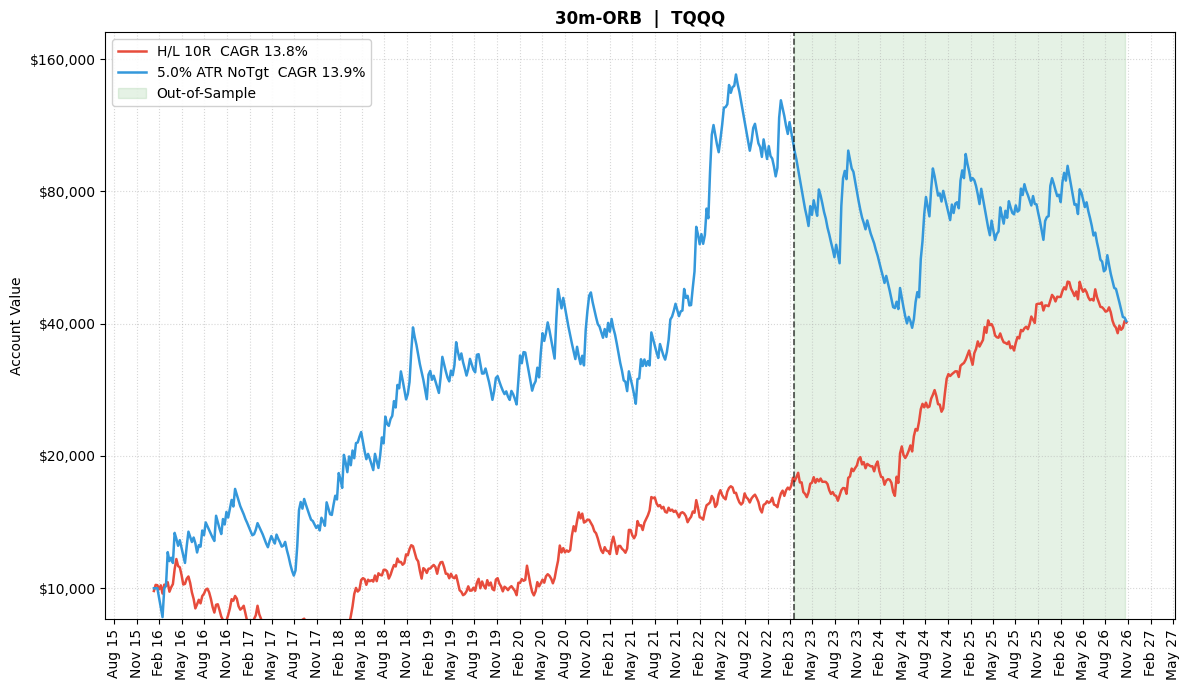

In [ ]:
OOS_DATE = "2023-02-17"

plot_equity_curves(all_results, AUM_0, orb_m, TICKER,
                   target_R_HL=target_R_HL, target_R_ATR=target_R_ATR,
                   stop_atr=stop_atr, oos_date=OOS_DATE);

### Performance Summary

In [ ]:
for stop_type, results in all_results.items():
    stop_label = f"Stop {stop_atr*100:.1f}% ATR" if stop_type == "ATR" else "Stop H/L"
    display(Markdown(f"#### {stop_label}"))
    summary_rows = []
    for name, result_df in results.items():
        returns = price2return(result_df['AUM'].values)
        if len(returns) == 0:
            continue
        stats = summary_statistics(returns)
        row = {m: v for m, v in zip(stats['Metric'], stats['Value'])}
        row['Provider'] = name
        summary_rows.append(row)
    display(pd.DataFrame(summary_rows).set_index('Provider'))

#### Stop H/L

,Total Return (%),CAGR (%),Volatility (%),Sharpe Ratio,Max Drawdown (%)
Provider,,,,,
Alpaca,302.37,13.80,25.33,0.63,-38.92


#### Stop 5.0% ATR

,Total Return (%),CAGR (%),Volatility (%),Sharpe Ratio,Max Drawdown (%)
Provider,,,,,
Alpaca,305.08,13.87,51.20,0.49,-73.47


### Monthly Returns

In [ ]:
for stop_type, results in all_results.items():
    stop_label = f"Stop {stop_atr*100:.1f}% ATR" if stop_type == "ATR" else "Stop H/L"
    display(Markdown(f"### {stop_label}"))
    for name, result_df in results.items():
        returns = price2return(result_df['AUM'].values)
        if len(returns) == 0:
            continue
        display(Markdown(f"#### {name}"))
        display(monthly_performance_table(returns, result_df['Date']))

### Stop H/L

#### Alpaca

month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,Year Total
year,,,,,,,,,,,,,
2016,-0.55%,0.71%,7.17%,-0.10%,-1.80%,-12.60%,5.59%,-4.94%,-3.44%,-4.82%,12.22%,-5.41%,-9.90%
2017,-9.19%,8.28%,-6.45%,1.06%,-2.94%,-5.56%,-2.91%,13.83%,-4.47%,-6.93%,-1.96%,0.32%,-17.65%
2018,3.39%,4.22%,21.36%,6.54%,-1.85%,2.30%,5.26%,0.95%,3.97%,3.12%,2.02%,-12.82%,41.74%
2019,6.51%,-2.69%,2.50%,-5.37%,-6.38%,-0.60%,0.58%,4.71%,-0.62%,3.41%,-5.35%,0.35%,-3.82%
2020,1.71%,9.39%,-12.69%,7.53%,1.03%,4.07%,8.62%,10.71%,10.08%,-2.60%,-6.34%,-10.35%,18.92%
2021,-0.62%,0.13%,0.18%,10.00%,5.25%,4.68%,10.75%,-5.39%,-0.48%,-2.42%,0.08%,0.96%,24.23%
2022,-1.77%,4.20%,0.30%,6.15%,2.81%,-3.35%,1.54%,0.57%,-8.46%,4.04%,-4.44%,10.87%,11.59%
2023,5.36%,0.26%,-6.94%,6.05%,0.09%,-0.79%,-6.11%,3.88%,6.68%,3.80%,1.60%,0.03%,13.62%
2024,-5.43%,-5.77%,-3.88%,27.58%,2.06%,8.11%,16.81%,3.25%,-5.98%,18.77%,1.26%,6.61%,75.30%


### Stop 5.0% ATR

#### Alpaca

month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,Year Total
year,,,,,,,,,,,,,
2016,-4.92%,5.57%,33.93%,-7.95%,7.95%,-8.82%,8.44%,-0.53%,4.02%,8.50%,15.02%,-11.72%,50.56%
2017,-9.29%,-1.22%,-3.99%,1.51%,-2.35%,-4.88%,-8.20%,36.24%,-3.88%,-7.45%,2.60%,5.32%,-2.48%
2018,22.29%,4.40%,5.42%,13.55%,-11.62%,-1.82%,8.06%,17.25%,15.51%,-8.46%,42.89%,-17.56%,109.29%
2019,2.61%,-8.58%,12.14%,-4.12%,6.86%,-7.99%,3.13%,-2.03%,-5.01%,4.49%,-9.51%,0.85%,-9.25%
2020,21.39%,-3.23%,-6.91%,26.05%,0.59%,14.57%,-1.77%,-17.81%,-7.67%,29.49%,-0.28%,-12.87%,33.22%
2021,3.22%,-6.10%,-17.26%,-3.17%,4.01%,10.82%,7.20%,-3.43%,19.94%,3.97%,9.81%,2.48%,30.05%
2022,37.77%,8.68%,50.26%,4.21%,22.01%,2.47%,-18.53%,-1.34%,-11.39%,-7.00%,-5.84%,40.02%,155.96%
2023,-8.97%,-17.79%,-21.17%,-3.06%,12.48%,-16.86%,-15.15%,54.04%,9.41%,-17.12%,-15.80%,-5.25%,-49.43%
2024,-13.76%,-7.67%,-12.83%,3.41%,-9.72%,16.42%,67.94%,13.81%,-13.00%,-7.86%,3.76%,16.62%,39.87%


In [ ]:
df = all_results['HL']['Alpaca'].copy()
df['Date'] = pd.to_datetime(df['Date'])
month_end = df.groupby(df['Date'].dt.to_period('M'))['AUM'].last()
print(month_end.pct_change().loc['2023-08'])
print("Final AUM:", df['AUM'].iloc[-1])

0.038779944267798516
Final AUM: 40236.57359999997


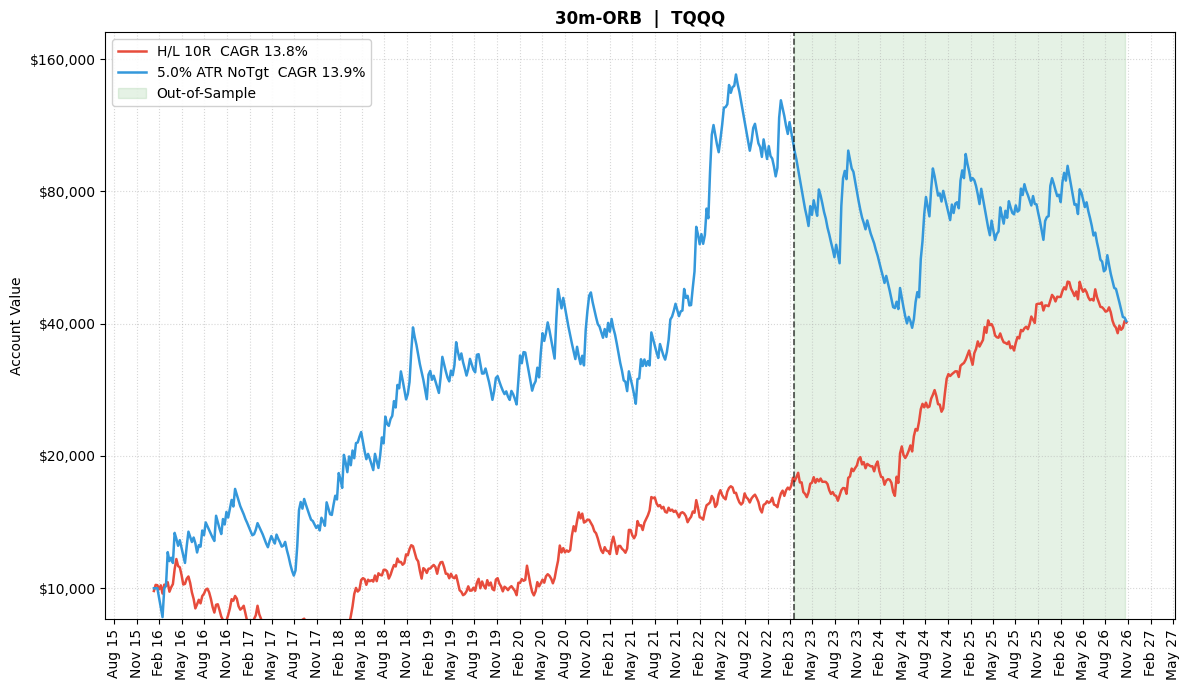

Total Return (%)  CAGR (%)  Volatility (%)  \
Strategy   Period                                                      
ORB HL     Full                     302.37     13.80           25.33   
           In-sample                 76.55      8.32           24.56   
           Out-of-sample            127.90     25.28           26.77   
ORB ATR    Full                     305.08     13.87           51.20   
           In-sample                894.82     38.11           52.03   
           Out-of-sample            -59.28    -21.80           49.44   
Buy & Hold Full                    3219.66     38.43           65.70   
           In-sample                453.98     27.20           68.84   
           Out-of-sample            499.23     63.22           59.12   

                          Sharpe Ratio  Max Drawdown (%)  
Strategy   Period                                         
ORB HL     Full                   0.63            -38.92  
           In-sample              0.45            -38.92  
           Out-of-sample          0.97            -24.99  
ORB ATR    Full                   0.49            -73.47  
           In-sample              0.86            -47.35  
           Out-of-sample         -0.27            -61.14  
Buy & Hold Full                   0.83            -81.66  
           In-sample              0.70            -81.66  
           Out-of-sample          1.12            -58.05

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import shutil
from google.colab import files

os.makedirs("results", exist_ok=True)
OOS_DATE = "2023-02-17"
OOS = pd.Timestamp(OOS_DATE)

# 1. Equity chart
fig, ax = plot_equity_curves(all_results, AUM_0, orb_m, TICKER,
                             target_R_HL=target_R_HL, target_R_ATR=target_R_ATR,
                             stop_atr=stop_atr, oos_date=OOS_DATE)
fig.savefig(f"results/{TICKER}_equity_chart_{TIMEFRAME}.png", dpi=200, bbox_inches="tight")

# 2. Summary table (Full / In-sample / Out-of-sample)
rows = []
def add_rows(label, ret_series):
    for period, s in [("Full", ret_series),
                      ("In-sample", ret_series[ret_series.index < OOS]),
                      ("Out-of-sample", ret_series[ret_series.index >= OOS])]:
        s = s.dropna()
        if len(s) < 20:
            continue
        st = summary_statistics(s.values)
        row = dict(zip(st['Metric'], st['Value']))
        row.update({"Strategy": label, "Period": period})
        rows.append(row)

for stop_type, results in all_results.items():
    df = results["Alpaca"]
    r = pd.Series(price2return(df['AUM'].values), index=pd.to_datetime(df['Date']))
    add_rows(f"ORB {stop_type}", r)

# Benchmark: buy and hold
bh = load_daily_csv(ALP_DAILY)
bh["day"] = pd.to_datetime(bh["day"])
bh = bh[(bh["day"] >= pd.Timestamp(START_DATE)) & (bh["day"] <= pd.Timestamp(END_DATE))].set_index("day")
add_rows("Buy & Hold", bh["close"].pct_change())

summary = pd.DataFrame(rows).set_index(["Strategy", "Period"]).astype(float)
summary.to_csv(f"results/{TICKER}_summary_{TIMEFRAME}.csv")
display(summary)

# 3. Monthly tables + 4. Equity curves
for stop_type, results in all_results.items():
    df = results["Alpaca"]
    monthly_performance_table(price2return(df['AUM'].values), df['Date'].values)\
        .to_csv(f"results/{TICKER}_monthly_{stop_type}_{TIMEFRAME}.csv")
    df.to_csv(f"results/{TICKER}_equity_{stop_type}_{TIMEFRAME}.csv", index=False)

# 5. Trade log
pd.DataFrame(trade_log).to_csv(f"results/{TICKER}_trades_{TIMEFRAME}.csv", index=False)

# 6. Raw data
shutil.copy(ALP_INTRADAY, "results/")
shutil.copy(ALP_DAILY, "results/")

# Zip and download
shutil.make_archive("orb_results", "zip", "results")
files.download("orb_results.zip")